<h1 style="text-align: center;"> Customer Churn Prediction and Retention Strategy Analysis with Business Impact Simulation </h1>


---  
### Executive Summary & Strategic Objectives

---  
**Business Problem**  
The purpose of this notebook is to build an interpretable classifier on the feature set selected in Notebook 1 `01_eda_and_feature_selection.ipynb`, to estimate the magnitude of the association of selected features with the churn behavior, and to simulate the potential financial impact of possible data-driven targeted retention interventions.

**Carried from Notebook 1**
- Preprocessed Telco dataset (7,043 rows × 20 columns)
- Stratified 70/30 train/test split (`random_state=60`)
- 13 features selected by XGBoost gain importance
- Exported artifacts: `df_train.csv`, `df_test.csv`, `selected_features.json`

**Objectives** 🔍

*✅ 1. What is the descriptive relationship between customer attributes and churn status?*  
*✅ 2. Which features carry the strongest predictive signal for churn, as ranked by XGBoost gain importance?*  
3. Using the top-ranked features, can customer churn be predicted, and which classifier — Logistic Regression or k-Nearest Neighbors — performs better?  
4. How can predicted churn probabilities be used to identify high-risk customers for targeted retention efforts?  
5. What is the estimated financial impact of targeting high-risk customers with a retention intervention?

**Outputs of This Notebook**
- Model comparison table (Accuracy, Recall, Specificity, Precision, F1, ROC-AUC, PR-AUC)
- ROC and Precision-Recall curves
- Risk tranches (Critical / High / Medium / Low)
- ROI simulation of the retention intervention

In [1]:
# Imported Libraries
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    brier_score_loss,
    f1_score,
    log_loss,
)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import SplineTransformer

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.contingency_tables import mcnemar

from scipy import stats
from scipy.special import logit
from prettytable import PrettyTable

---  
## <center> Objective 3: </center>
## <center> Using the top-ranked features, can customer churn be predicted, and which classifier — Logistic Regression or k-Nearest Neighbors — performs better? </center>

#### Analytical Plan

1. **Load and prepare the modeling data.** Confirm train/test shapes and matching churn rates.
2. **Build the k-Nearest Neighbors model.** Check assumptions, scale features, tune `k` via 5-fold CV on PR-AUC (Precision-Recall AUC curve).
3. **Build the Logistic Regression model.** Check assumptions, tune `C` (inverse regularization strength) via CV.
4. **Compare models at tuned F1-optimal thresholds.** Report confusion matrices and core metrics.
5. **Validate assumptions and interpret coefficients.** Re-check collinearity, test logit linearity, inspect coefficients with CIs.
6. **Assess calibration and discrimination.** Reliability diagram, ROC/PR curves, bootstrap and McNemar tests.

In [2]:
# Load train-test data from Notebook 1
df_train = pd.read_csv('df_train.csv')
df_test = pd.read_csv('df_test.csv')

with open('selected_features.json') as f:
    selected_features = json.load(f)

print(f"Train shape: {df_train.shape}")
print(f"Test shape:  {df_test.shape}")
print(f"Selected features ({len(selected_features)}):")
for i, feature in enumerate(selected_features, 1):
    print(f"  {i:2d}. {feature}")

Train shape: (4930, 14)
Test shape:  (2113, 14)
Selected features (13):
   1. Contract_Two year
   2. InternetService_Fiber optic
   3. Contract_One year
   4. InternetService_No
   5. PaymentMethod_Electronic check
   6. tenure
   7. PaperlessBilling_Yes
   8. OnlineSecurity_Yes
   9. TotalCharges
  10. SeniorCitizen_Yes
  11. StreamingTV_Yes
  12. StreamingMovies_Yes
  13. MonthlyCharges


In [3]:
# Separate predictors from target
X_train = df_train[selected_features]
y_train = df_train['Churn']
X_test = df_test[selected_features]
y_test = df_test['Churn']

print(f"X_train: {X_train.shape}   y_train churn rate: {y_train.mean():.4f}")
print(f"X_test:  {X_test.shape}   y_test churn rate:  {y_test.mean():.4f}")

X_train: (4930, 13)   y_train churn rate: 0.2653
X_test:  (2113, 13)   y_test churn rate:  0.2655


## k-Nearest Neighbors Classification Model

### Model Assumptions for k-Nearest Neighbors Classifier

K-Nearest Neighbors relies on the following assumptions and properties (James et al., 2023, pp. 111-115):

1. **No parametric form is assumed for $f(X)$.** KNN is a non-parametric method, meaning it does not assume a specific functional shape (such as linearity) for the relationship between predictors and response. ✅
2. **Local constancy / similarity assumption.** The method assumes that observations close together in predictor space have similar response values. It estimates $f(x_0)$ (the true response at target point $x_0$) by averaging the responses of the $K$ nearest training observations in the neighboorhood set $\mathcal{N}_0$.
   - *How well this holds for the mixed binary/continuous feature space will be evaluated after the analyses.* ⏳
3. **Low-dimensional setting ($p$ small relative to $n$).** KNN requires a large number of observations relative to the number of predictors. In higher dimensions, nearest neighbors may be very far from the target point, leading to poor predictions — the so-called *curse of dimensionality*.
   - In this dataset, $p=13$ predictors (10 of which are binary indicator variables) and $n=4,930$ training samples represent a moderate-dimensional setting, making the curse of dimensionality a mild but relevant concern. ✅
4. **The true relationship is not linear.** KNN is most advantageous when the underlying relationship is non-linear; if the true relationship is linear, KNN incurs a variance cost that is not offset by a reduction in bias, and linear regression will typically outperform it. 
   - *Whether the true relationship is non-linear in this dataset will be discussed after the model comparison.* ⏳
5. **Choice of $K$ reflects a bias–variance trade-off.** A small $K$ gives a flexible, low-bias but high-variance fit; a large $K$ gives a smoother, low-variance but higher-bias fit. The optimal $K$ depends on this trade-off and is typically chosen via cross-validation (pp. 111–112).
   - The optimal $K$ is selected (below) using 5-fold stratified cross-validation, directly addressing this bias–variance trade-off. ✅

**Hyperparameter Tuning: Finding the best k**

In [4]:
# Choosing k range from 1 to 100
k_value_min = 1
k_value_max = 100

In [5]:
# Scaling the features

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"Min per column: {X_train_scaled.min(axis=0)}")
print(f"Max per column: {X_train_scaled.max(axis=0)}")

X_train_scaled shape: (4930, 13)
Min per column: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Max per column: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [7]:
knn_pipe = make_pipeline(MinMaxScaler(), KNeighborsClassifier(weights='distance'))
knn_grid = GridSearchCV(
    estimator=knn_pipe,
    param_grid={'kneighborsclassifier__n_neighbors': range(k_value_min, k_value_max + 1)},
    scoring='average_precision',
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    n_jobs=-1
)
knn_grid.fit(X_train, y_train)   # unscaled but scaling happens inside each fold

results = pd.DataFrame(knn_grid.cv_results_)
mean_scores = results['mean_test_score']
params = results['param_kneighborsclassifier__n_neighbors']

max_score = mean_scores.max()

# Find the best k values within 0.5% tolerance of the peak
tolerance = 0.005 
valid_ks = params[mean_scores >= (max_score - tolerance)]
best_k_robust = valid_ks.min()

print(f"Peak CV PR-AUC:          {max_score:.4f} (at k={params[mean_scores.idxmax()]})")
print(f"Chosen k (robust):       {best_k_robust}")

Peak CV PR-AUC:          0.6010 (at k=94)
Chosen k (robust):       41


> **Key Insights — KNN Hyperparameter Tuning** 📊
>
> - **Tuning is done on PR-AUC, not accuracy,** because the data is imbalanced (~26.5% churn). A no-skill classifier already scores 73.5% accuracy, so accuracy would reward majority-class bias; PR-AUC reflects minority-class performance.
> - **Peak CV PR-AUC is 0.6010, reached at k=94**. 
> - **k=41 selected as the robust choice** — the smallest k within 0.005 PR-AUC of the peak (0.6010 at k=94). Because class imbalance is handled afterwards through the decision threshold, this rule simply favors the smaller, more local model at no meaningful PR-AUC cost.
> - **Methodological note:** k is selected via 5-fold stratified cross-validation on the training set using PR-AUC, then evaluated once on the held-out test set — no test-set leakage during model selection.
> - **Consistency note:** The k-sweep uses distance-weighted KNN (matching the final model), so tuning and deployment share the same algorithm.

#### Performing KNN Model

In [8]:
# Define the classification model
knn_model = KNeighborsClassifier(n_neighbors=best_k_robust, weights='distance')
knn_model.fit(X_train_scaled, y_train)

,n_neighbors,41
,weights,'distance'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [9]:
# Predict and compute the accuracy on the test data
y_pred_knn = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_pred_knn)
print(f"KNN Model Accuracy: {knn_accuracy:.4f}")

KNN Model Accuracy: 0.7875


## Logistic Regresssion Model

### Model Assumptions for Logistic Regression

The assumptions of logistic regression (Lomax \& Hahs-Vaughn, 2012) are somewhat relaxed compared to OLS regression, but four primary assumptions must still be considered:

1. **Noncollinearity.** Predictors should not be highly correlated with one another, as this inflates standard errors and makes coefficient estimates unstable.
   - This dataset includes `tenure`, `MonthlyCharges`, and `TotalCharges`, which are structurally related (`TotalCharges ≈ tenure × MonthlyCharges`). *How the model handles this overlap will be evaluated after the analysis and further decisions will be made based on the analysis results.* ⏳
2. **Linearity (of the logit).** The log-odds of the outcome must be a linear function of the predictors.
   - *Whether this holds for all features (especially `tenure`) will be discussed after the model analysis.* ⏳
3. **Independence of errors.** Each observation should be independent of the others.
   - This is satisfied by design: each row represents a distinct customer, with no repeated measures over time or across accounts. ✅
4. **Values of $X$ are fixed.** The predictors are assumed to be measured without error, or their errors are independent of the outcome.
   - This is treated as satisfied for a predictive model: billing amounts and tenure are administrative records, not noisy self-reports. ✅

Two further practical checks:
- **Large sample size:** With $n=4,930$ training samples, 13 predictors, and roughly 100 events per variable, the sample is well above the practical rule of thumb (≥10 cases per variable). ✅
- **Influential outliers:** `MinMaxScaler` is sensitive to extreme values (unlike standardization). While outliers were identified in the exploratory phase (Notebook 1), they were retained because they are plausible billing values rather than data entry errors. No observations were dropped. ✅

In [10]:
X_vif = sm.add_constant(X_train.astype(float))
vif_data = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif_data = (vif_data[vif_data["Feature"] != "const"]
            .sort_values("VIF", ascending=False).reset_index(drop=True))
display(vif_data)

,Feature,VIF
0,MonthlyCharges,21.724220
1,TotalCharges,10.461197
2,tenure,7.064387
3,InternetService_Fiber optic,6.437509
4,InternetService_No,4.281452
5,Contract_Two year,2.505682
6,StreamingTV_Yes,2.157487
7,StreamingMovies_Yes,2.152937
8,Contract_One year,1.573141
9,OnlineSecurity_Yes,1.567004


**Key Insights for LR Model Assumption 1:**

- A VIF check (computed with an intercept) shows strong overlap among MonthlyCharges (VIF = 21.72) and TotalCharges (10.46) and some collinearity with tenure (7.06), as expected since TotalCharges ≈ tenure × MonthlyCharges.
- Collinearity inflates the variance of individual coefficients but does not materially hurt predictive accuracy.
- The coefficients of these three variables are therefore not interpreted individually; confidence intervals are reported below.

In [11]:
# Tune Logistic Regression using Cross-Validation on the training set
print("Tuning Logistic Regression...")
lr_pipe = make_pipeline(MinMaxScaler(), LogisticRegression(max_iter=10000, random_state=42))
lr_grid = GridSearchCV(
    estimator=lr_pipe,
    param_grid={'logisticregression__C': [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]}, 
    scoring='average_precision',
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    n_jobs=-1
)
lr_grid.fit(X_train, y_train)
best_C = lr_grid.best_params_['logisticregression__C']
log_model = LogisticRegression(C=best_C, max_iter=10000, random_state=42).fit(X_train_scaled, y_train)
print(f"Best C found via CV: {best_C}")
print(f"Best CV PR-AUC:      {lr_grid.best_score_:.4f}")

Tuning Logistic Regression...
Best C found via CV: 10.0
Best CV PR-AUC:      0.6343


---  
## Model Comparison  

To compare models, the metrics below are utilized:


| Metric Name | Mathematical Formula |
|---|---|
| **Accuracy** | $\dfrac{TP + TN}{TP + TN + FP + FN}$ |
| **Recall** (Sensitivity) | $\dfrac{TP}{TP + FN}$ |
| **Specificity** | $\dfrac{TN}{TN + FP}$ |
| **Precision** | $\dfrac{TP}{TP + FP}$ |
| **F1-Score** | $\dfrac{2 \cdot TP}{2 \cdot TP + FP + FN}$ |

The `metric_scores` dictionary below stores the five metric scores for each model. The first element in each list corresponds to the **KNN** classifier; the second to **Logistic Regression**.

In [12]:
metric_scores = {}

# 1. Get KNN probabilities
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

# 2. Logistic regression probabilities (unweighted model, already on the natural scale)
y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

cv5 = StratifiedKFold(5, shuffle=True, random_state=42)

knn_oof_pipe = make_pipeline(
    MinMaxScaler(),
    KNeighborsClassifier(n_neighbors=best_k_robust, weights='distance')
)
log_oof_pipe = make_pipeline(
    MinMaxScaler(),
    LogisticRegression(C=best_C, max_iter=10000, random_state=42)
)

# raw X_train: the scaler is re-fit on the training part of each fold only
oof_knn = cross_val_predict(knn_oof_pipe, X_train, y_train, cv=cv5, method='predict_proba')[:, 1]
oof_log = cross_val_predict(log_oof_pipe, X_train, y_train, cv=cv5, method='predict_proba')[:, 1]

# Threshold search
grid = np.arange(0.10, 0.71, 0.01)
thr_knn = grid[np.argmax([f1_score(y_train, oof_knn >= t) for t in grid])]
thr_log = grid[np.argmax([f1_score(y_train, oof_log >= t) for t in grid])]
print(f"Decision thresholds on the predicted churn probability, chosen on training CV (max F1): KNN={thr_knn:.2f}, LR={thr_log:.2f}")

y_pred_knn = (y_prob_knn >= thr_knn).astype(int)
y_pred_log = (y_prob_log >= thr_log).astype(int)


# Extract confusion_matrix for kNN
tn_k, fp_k, fn_k, tp_k = confusion_matrix(y_test, y_pred_knn).ravel()

# Extract confusion_matrix for logistic regression
tn_l, fp_l, fn_l, tp_l = confusion_matrix(y_test, y_pred_log).ravel()


metric_scores['Accuracy'] = [
    (tp_k + tn_k) / (tp_k + tn_k + fp_k + fn_k),
    (tp_l + tn_l) / (tp_l + tn_l + fp_l + fn_l)
]

metric_scores['Recall'] = [
    tp_k / (tp_k + fn_k),
    tp_l / (tp_l + fn_l)
]

metric_scores['Specificity'] = [
    tn_k / (tn_k + fp_k),
    tn_l / (tn_l + fp_l)
]

metric_scores['Precision'] = [
    tp_k / (tp_k + fp_k),
    tp_l / (tp_l + fp_l)
]

metric_scores['F1-score'] = [
    (2 * tp_k) / (2 * tp_k + fp_k + fn_k),
    (2 * tp_l) / (2 * tp_l + fp_l + fn_l)
]

Decision thresholds on the predicted churn probability, chosen on training CV (max F1): KNN=0.33, LR=0.31


#### Confusion matrices

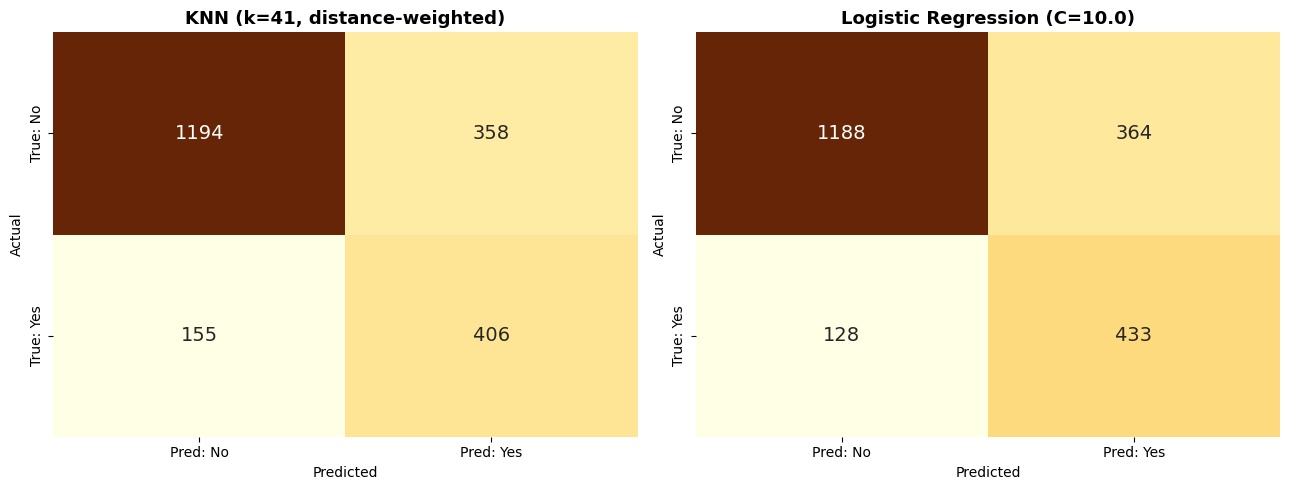

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, y_pred) in zip(axes, [
    (f'KNN (k={best_k_robust}, distance-weighted)', y_pred_knn),
    (f'Logistic Regression (C={log_model.C})', y_pred_log),
]):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrBr', cbar=False,
                xticklabels=['Pred: No', 'Pred: Yes'],
                yticklabels=['True: No', 'True: Yes'],
                annot_kws={'size': 14}, ax=ax)
    ax.set_title(name, fontsize=13, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig('images/confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

In [14]:
# Sanity check: all metric values are valid probabilities
for metric, scores in metric_scores.items():
    assert all(0 <= s <= 1 for s in scores), f"{metric} out of range"

assert set(metric_scores.keys()) == {'Accuracy', 'Recall', 'Specificity', 'Precision', 'F1-score'}, \
    "Unexpected metric keys"
print("✅ All metrics within [0, 1] and expected keys present.")

✅ All metrics within [0, 1] and expected keys present.


In [15]:
# Display the results
df_model_results = pd.DataFrame(metric_scores, index=['kNN Model', 'Logistic Regression Model'])
df_formatted = (df_model_results.T*100).map(lambda x: f"{x:.1f}%")
display(df_formatted)

,kNN Model,Logistic Regression Model
Accuracy,75.7%,76.7%
Recall,72.4%,77.2%
Specificity,76.9%,76.5%
Precision,53.1%,54.3%
F1-score,61.3%,63.8%


In [16]:
# Diagnostic for the multicollinearity problem: Does Dropping TotalCharges Matter?
cv5 = StratifiedKFold(5, shuffle=True, random_state=42)

# 1) What the fitted (penalized) model actually estimates
print("Fitted (penalized) coefficients: ")

print(pd.Series(log_model.coef_[0], index=selected_features)
        [['tenure', 'TotalCharges', 'MonthlyCharges']].round(2))

# 2) VIF after removing the redundant TotalCharges
print("\nVIFs after removing the redundant TotalCharges: ")

feats_noTC = [f for f in selected_features if f != 'TotalCharges']
Xv = sm.add_constant(X_train[feats_noTC].astype(float))
print(pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=feats_noTC).round(2).sort_values(ascending=False).head(4))

# 3) Predictive cost of dropping TotalCharges
print("\nPredictive cost of dropping TotalCharges:")

for name, cols in [('all 13 features', selected_features), ('without TotalCharges', feats_noTC)]:
    pipe = make_pipeline(MinMaxScaler(),
                         LogisticRegression(C=best_C, max_iter=10000, random_state=42))
    oof = cross_val_predict(pipe, X_train[cols], y_train, cv=cv5, method='predict_proba')[:, 1]
    print(f"{name:22s} PR-AUC={average_precision_score(y_train, oof):.4f}  "
          f"ROC-AUC={roc_auc_score(y_train, oof):.4f}  log-loss={log_loss(y_train, oof):.4f}")

Fitted (penalized) coefficients: 
tenure           -3.90
TotalCharges      2.55
MonthlyCharges   -1.91
dtype: float64

VIFs after removing the redundant TotalCharges: 
MonthlyCharges                 17.72
InternetService_Fiber optic     6.35
InternetService_No              4.18
Contract_Two year               2.49
dtype: float64

Predictive cost of dropping TotalCharges:
all 13 features        PR-AUC=0.6309  ROC-AUC=0.8398  log-loss=0.4234
without TotalCharges   PR-AUC=0.6287  ROC-AUC=0.8379  log-loss=0.4247


> **Key Insights — Model Comparison** 📊
>
> - **Logistic Regression leads on Accuracy, Recall, Precision and F1, while KNN is marginally higher on Specificity:** \[LR vs KNN\, respectively], Accuracy (76.7% vs. 75.7%), Recall (77.2% vs. 72.4%), Specificity (76.5% vs. 76.9%), Precision (54.3% vs. 53.1%) and F1 (63.8% vs. 61.3%). Each model is evaluated at its own threshold, chosen by maximizing F1 on out-of-fold training predictions (KNN 0.33, LR 0.31). So this is not a matched-threshold comparison, but rather a model comparison.
> - **Accuracy is a weak discriminator here.** With a 26.5% churn rate, a naive "everyone stays" classifier already scores 73.5% — KNN (75.7%) clears that floor by only about 2 points and LR (76.7%) by about 3, so precision, F1 and the threshold-free metrics are more informative. The recall gap between the models is moderate (4.8 pts); the clearer separation is in precision (1.2 pts) and F1 (2.5 pts), where LR's advantage is consistent but small.
> - **The threshold-free metrics confirm the same ranking.** ROC-AUC (0.852 vs. 0.814) and PR-AUC (0.657 vs. 0.601) are both computed at every threshold, so LR's advantage does not depend on the cutoffs used for the confusion matrices (0.31 for LR, 0.33 for KNN).
> - **F1-score is the headline: LR wins at 63.8% vs. 61.3%.** F1 balances precision and recall at each model's own operating point; the threshold-free metrics above show the advantage holds beyond those points.
> - **Business implication:** in a retention context, the cost of a false negative (lost customer revenue) typically outweighs the cost of a false positive (an unnecessary retention offer). At its F1-optimal threshold of 0.31, LR flags 77.2% of churners — with slightly higher precision than KNN as well (54.3% vs. 53.1%) — so each dollar of campaign spend reaches more real churners. Note that the ROI simulation in Objective 5 targets customers with P ≥ 0.50, a stricter cutoff that reaches fewer churners (54.9%).

---  
### Logistic Regression Coefficients — Feature Interpretation

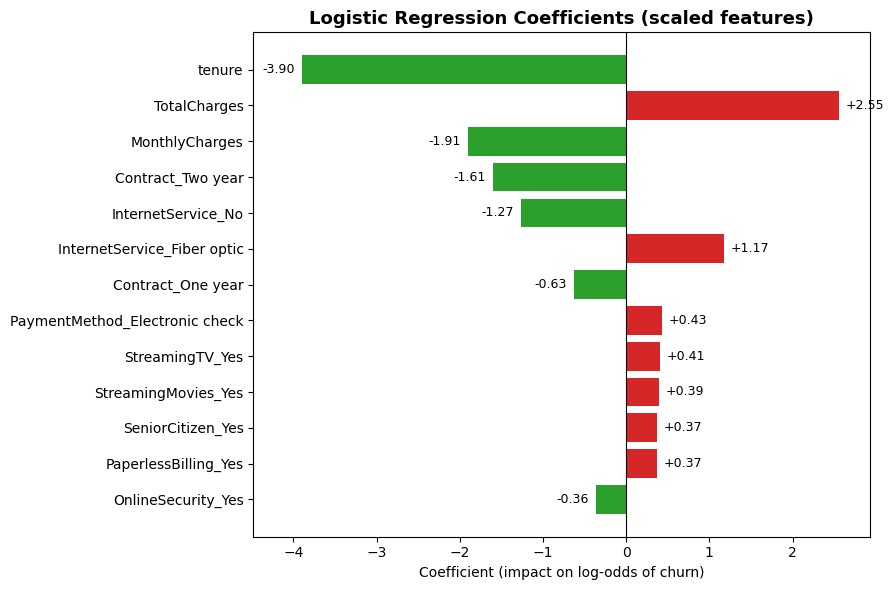

In [17]:
coef_df = pd.DataFrame({
    'Feature': selected_features,
    'Coefficient': log_model.coef_[0] # coefficients in log-odds space (features were MinMax-scaled)
}).sort_values('Coefficient', key=abs, ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
colors = ['#d62728' if c > 0 else '#2ca02c' for c in coef_df['Coefficient']]
bars = ax.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Logistic Regression Coefficients (scaled features)', fontsize=13, fontweight='bold')
ax.set_xlabel('Coefficient (impact on log-odds of churn)')

# Add numeric labels to each bar
ax.bar_label(bars, labels=[f'{c:+.2f}' for c in coef_df['Coefficient']], 
             padding=5, fontsize=9)

# Extend x-axis limits 
ax.set_xlim(coef_df['Coefficient'].min() * 1.15, coef_df['Coefficient'].max() * 1.15)

plt.tight_layout()
plt.savefig('images/lr_coefficients.png', dpi=300, bbox_inches='tight')
plt.show()

In [18]:
# A second logistic regression, using statsmodels instead of scikit-learn; 
# statsmodels gives intervals and p-values, which sklearn doesn’t provide directly
Xc = sm.add_constant(pd.DataFrame(X_train_scaled, columns=selected_features))
logit_fit = sm.Logit(y_train.values, Xc).fit(disp=0)
ci = logit_fit.conf_int()
coef_table = pd.DataFrame({'coef': logit_fit.params, 'ci_low': ci[0],
                           'ci_high': ci[1], 'p_value': logit_fit.pvalues}).round(3)
display(coef_table)

,coef,ci_low,ci_high,p_value
const,-0.049,-0.441,0.342,0.805
Contract_Two year,-1.610,-2.020,-1.200,0.000
InternetService_Fiber optic,1.191,0.791,1.591,0.000
Contract_One year,-0.617,-0.861,-0.372,0.000
InternetService_No,-1.296,-1.702,-0.890,0.000
PaymentMethod_Electronic check,0.429,0.269,0.590,0.000
tenure,-4.142,-5.181,-3.102,0.000
PaperlessBilling_Yes,0.369,0.196,0.543,0.000
OnlineSecurity_Yes,-0.356,-0.559,-0.152,0.001
TotalCharges,2.892,1.465,4.319,0.000


In [19]:
# Linearity assumption check
d = X_train.astype(float).copy()
d.columns = d.columns.str.replace(r'\W+', '_', regex=True)
d['Churn'] = y_train.values
terms = list(d.columns.drop('Churn'))
base = smf.logit('Churn ~ ' + ' + '.join(terms), d).fit(disp=0)

for v in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    f = 'Churn ~ ' + ' + '.join([f'cr({t}, df=4)' if t == v else t for t in terms]) # cr a natural cubic spline with 4 degrees of freedom
    sp = smf.logit(f, d).fit(disp=0)
    lr_stat = 2 * (sp.llf - base.llf)
    df_diff = sp.df_model - base.df_model
    print(f"{v:15s} LR stat = {lr_stat:7.2f}, df = {df_diff:.0f}, p = {stats.chi2.sf(lr_stat, df_diff):.4g}")

tenure          LR stat =   45.65, df = 2, p = 1.22e-10
MonthlyCharges  LR stat =    4.70, df = 2, p = 0.09543
TotalCharges    LR stat =   28.86, df = 2, p = 5.411e-07


In [20]:
# Practical cost of non-linearity (linearity rejected in In [19])
nonlinear = ['tenure', 'TotalCharges']   
lin_pipe = make_pipeline(
    MinMaxScaler(),
    LogisticRegression(C=best_C, max_iter=10000, random_state=42)
)
spline_pipe = make_pipeline(
    ColumnTransformer(
        [('spl', SplineTransformer(n_knots=5, degree=3, include_bias=False), nonlinear)],
        remainder=MinMaxScaler()
    ),
    LogisticRegression(C=best_C, max_iter=10000, random_state=42)
)

for name, pipe in [('Linear logit', lin_pipe), ('Spline logit', spline_pipe)]:
    oof = cross_val_predict(pipe, X_train, y_train, cv=cv5, method='predict_proba')[:, 1]
    print(f"{name:13s} PR-AUC={average_precision_score(y_train, oof):.4f}  "
          f"ROC-AUC={roc_auc_score(y_train, oof):.4f}  log-loss={log_loss(y_train, oof):.4f}")

Linear logit  PR-AUC=0.6309  ROC-AUC=0.8398  log-loss=0.4234
Spline logit  PR-AUC=0.6445  ROC-AUC=0.8441  log-loss=0.4179


**A Linearity check: Does it matter predictively?**  
A spline-augmented logistic model (cross-validated on the training set) improved PR-AUC by about 0.014, ROC-AUC by 0.004 and log-loss by 0.006 relative to the linear model. Non-linearity in tenure and TotalCharges is statistically detectable but has only a small predictive cost. Because Splines would make the coefficients much harder to interpret, the linear model is retained for interpretability.

**Key Insights — Logistic Regression Coefficients 📊**

*Estimates and confidence intervals are from the unpenalized fit in In [18]; the penalized model plotted above gives very similar values (e.g., tenure −3.90, MonthlyCharges −1.91). All features are MinMax-scaled, so a continuous coefficient is the effect of moving across the variable's full range.*

- **Contract type is the clearest protective factor.** A two-year contract has an odds ratio of about 0.20 (95% CI 0.13–0.30) relative to month-to-month, and a one-year contract about 0.54 (0.42–0.69), holding the other features fixed.
- **Fiber-optic service is the strongest non-billing risk factor.** Its odds ratio is about 3.3 (2.2–4.9) relative to DSL. Customers with no internet service have lower odds (about 0.27, 0.18–0.41), also relative to DSL.
- **Smaller risk-increasing factors:** electronic-check payment, paperless billing, senior-citizen status, StreamingTV and StreamingMovies each add roughly 0.37–0.43 to the log-odds (odds ratios about 1.4–1.5), and OnlineSecurity lowers them (about −0.36, odds ratio 0.70).
- **tenure, TotalCharges and MonthlyCharges are not interpreted individually.** Their coefficients are large and partly offsetting (tenure −4.14, TotalCharges +2.89, MonthlyCharges −2.03) because TotalCharges ≈ tenure × MonthlyCharges (VIFs 7–22). They are jointly significant, and the model uses them together; none can be called the "strongest" or "effectively zero". In particular, XGBoost's low ranking of MonthlyCharges is not evidence that it has no association with churn.
- **Business takeaway:** the highest-risk profile is a month-to-month, fiber-optic customer paying by electronic check. These are associations, not causal effects, so whether a contract upgrade or fiber offer reduces churn needs the experimental test described in the final section.

**Methodological note: how the odds ratios are obtained.** The coefficient table (In [18]) reports log-odds coefficients and their 95% confidence limits. The odds ratios quoted in these insights are not printed by any cell; they are computed as $\mathrm{OR} = e^{\hat\beta}$, and the confidence limits of the odds ratio are obtained by applying the same transformation to the confidence limits of the coefficient, $\left(e^{\beta_{\text{low}}},\ e^{\beta_{\text{high}}}\right)$. Because the transformation is monotonic, an interval that excludes 0 on the log-odds scale excludes 1 on the odds-ratio scale. Each odds ratio compares a category with the reference category (month-to-month contract), holding the other features fixed. For example:

| Contract | Coefficient (95% CI) | Odds ratio (95% CI) |
|---|---|---|
| Two year | −1.610 (−2.020, −1.200) | $e^{-1.610} = 0.20$ (0.13, 0.30) |
| One year | −0.617 (−0.861, −0.372) | $e^{-0.617} = 0.54$ (0.42, 0.69) |

The inputs are the rounded values from the table (3 decimals), so the odds ratios are approximate. They are associations estimated from the unpenalized fit.

---  
> **Checking the Remaining Assumptions:**  
> - **Why KNN underperforms (Assumptions 2 & 4):** KNN assumes that nearby points in feature space share the same label (Assumption 2). This is probably only weakly satisfied here: 10 of the 13 features are one-hot encoded, so a single categorical mismatch adds 1.0 to the squared Euclidean distance, which is large relative to typical differences in the MinMax-scaled continuous features (tenure, MonthlyCharges, TotalCharges). Neighbors may therefore be determined mostly by categorical overlap rather than by overall similarity. This is a plausible explanation and was not tested directly. KNN’s flexibility is only an advantage when the true relationship is strongly non-linear (Assumption 4). The spline tests show non-linearity in tenure and TotalCharges, but the KNN’s lower performance means that the non-linearity is not strong or localized enough for KNN to exploit it. LR’s advantage over KNN should not be read as evidence that the relationship is linear. 

> - **Multicollinearity for LR (Assumption 1):** The VIF check flagged strong collinearity among tenure, MonthlyCharges and TotalCharges (TotalCharges ≈ tenure × MonthlyCharges). L2 regularization stabilizes the estimates but does not resolve the collinearity or identify a "primary driver": with C = 10 the penalty is weak, and the fitted coefficients on the scaled features are large and partly offsetting (tenure −3.90, TotalCharges +2.55, MonthlyCharges −1.91), with wide confidence intervals. These three coefficients are therefore not interpreted individually. Removing TotalCharges removes the tenure overlap (tenure's VIF falls below 2.5), but MonthlyCharges stays high (VIF 17.7, down from 21.7), largely because of its overlap with the InternetService indicators, and cross-validated performance is essentially unchanged (PR-AUC 0.6309 → 0.6287, ROC-AUC 0.8398 → 0.8379, log-loss 0.4234 → 0.4247). Collinearity therefore limits coefficient interpretation but has no meaningful effect on prediction, so all 13 features are retained.

> - **Linearity of the logit for LR (Assumption 2):** Likelihood-ratio tests against natural cubic splines (In [19]) reject linearity for tenure (p ≈ 1e-10) and TotalCharges (p ≈ 5e-7), but not for MonthlyCharges (p = 0.095). The assumption is therefore violated for two of the three continuous predictors. A spline-augmented logistic model (cross-validated on the training set) improved PR-AUC by about 0.014, ROC-AUC by 0.004 and log-loss by 0.006 relative to the linear model. Non-linearity in tenure and TotalCharges is statistically detectable but has only a small predictive cost, so the linear model is retained for interpretability.
> - **Influential outliers:** Extreme values were retained in the training set because they are plausible billing amounts. `MinMaxScaler` does not neutralize outliers, but strong out-of-fold AUC and good calibration on the test set (slope 1.07) suggest the fit is not badly distorted. This was not tested directly with influence diagnostics (e.g., Cook's distance, leverage) though.

### Model Diagnostics: ROC Curve & Threshold Analysis

In [21]:
# Predict probabilities for the positive class using the fitted KNN model
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]
print(knn_model.classes_)   #  check if col 1 = churn

[0 1]


In [22]:
# Predict probabilities for the positive class using the fitted Logistic Regression model
y_prob_logreg = log_model.predict_proba(X_test_scaled)[:, 1]

#### Probability Calibration  
The logistic regression is fit without class weights, so its outputs estimate P(churn | x) on the natural scale. Class imbalance is handled at the decision stage by choosing a threshold, not by resampling or reweighting the training data (van den Goorbergh et al., 2022). Calibration is verified on the held-out test set using a reliability diagram, calibration slope and intercept, and the Brier score.

Test churn rate:      0.265
Mean predicted prob:  0.267
Brier score:          0.1331  (constant-prediction reference 0.1950)
Calibration slope:    1.07  (95% CI 0.97-1.18)
Calibration intercept:-0.01


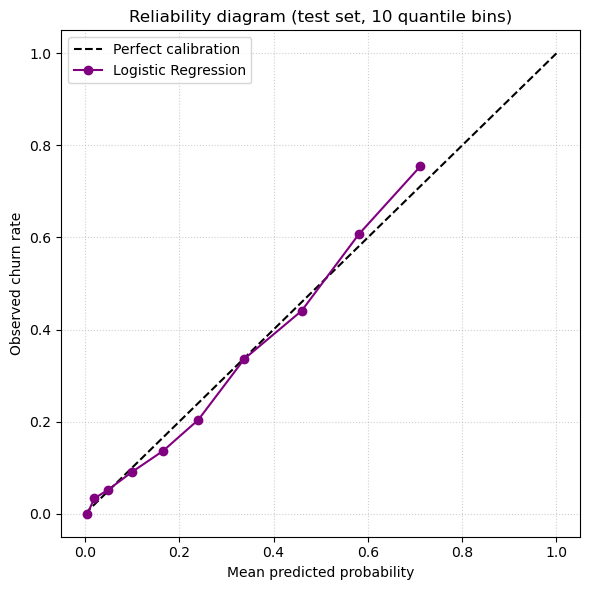

In [23]:
# Calibration check
p = np.clip(y_prob_logreg, 1e-6, 1 - 1e-6) # the logit is infinite at 0 and 1
lp = logit(p) # converting clipped probabilities to log-odds

# Calibration slope (ideal would be 1)
slope_fit = sm.Logit(y_test, sm.add_constant(lp)).fit(disp=0) # disp=0 : no convergence details
cal_slope = slope_fit.params.iloc[1]
cal_slope_ci = slope_fit.conf_int().iloc[1].values

# Calibration-in-the-large (estimate intercept with slope fixed at 1; ideal = 0)
citl_fit = sm.GLM(y_test, np.ones(len(lp)), family=sm.families.Binomial(),
                  offset=lp).fit() 
cal_citl = citl_fit.params.iloc[0]

brier = brier_score_loss(y_test, p) # standard Brier score loss function from scikit learn
brier_ref = y_test.mean() * (1 - y_test.mean())   # constant-prediction Brier
print(f"Test churn rate:      {y_test.mean():.3f}")
print(f"Mean predicted prob:  {p.mean():.3f}")
print(f"Brier score:          {brier:.4f}  (constant-prediction reference {brier_ref:.4f})")
print(f"Calibration slope:    {cal_slope:.2f}  (95% CI {cal_slope_ci[0]:.2f}-{cal_slope_ci[1]:.2f})")
print(f"Calibration intercept:{cal_citl:+.2f}")

# Reliability diagram
frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
ax.plot(mean_pred, frac_pos, marker='o', color='purple', label='Logistic Regression')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Observed churn rate')
ax.set_title('Reliability diagram (test set, 10 quantile bins)')
ax.legend(); ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('images/reliability_diagram.png', dpi=300, bbox_inches='tight')
plt.show()

**Key insights — Probability Calibration 📊**  
- The model is well-calibrated, with a Brier score of 0.1331, outperforming the reference model. The calibration slope of 1.07 (with 95% CI 0.97-1.18) and intercept of -0.01 indicate negligible bias, while the reliability diagram confirms highly reliable probability predictions.

#### ROC (Receiver Operating Characteristic) Curve

The ROC curve traces a binary classifier's performance across all possible **decision thresholds** — the cut-off applied to predicted probabilities to assign the positive class. For each threshold, the model's false positive rate and true positive rate are computed:

$$\text{False Positive Rate} = \frac{FP}{TN + FP} \qquad \text{True Positive Rate} = \frac{TP}{TP + FN}$$

The curve is then plotted as TPR vs. FPR. A model that perfectly separates the classes reaches the top-left corner (FPR = 0, TPR = 1); a model with no discriminative ability lies on the diagonal.  

#### Thresholds

A threshold is the cut-off applied to a predicted probability to assign the positive class — in this context, the probability above which a customer is flagged as at-risk of churn. Threshold choice directly trades off true positives against false positives.

Rather than evaluating a static grid of thresholds, the ROC curve sweeps every unique predicted probability produced by the model. This gives an exact curve with no redundant computation, since each unique probability represents a distinct point where the model's classifications change.

In [24]:
def get_thresholds(y_pred_proba):
    """Return sorted unique thresholds, padded to force ROC endpoints."""
    unique_probas = np.unique(y_pred_proba)[::-1]

    # Insert 1.1 → forces (FPR=0, TPR=0), the lower-left corner
    # Append 0  → forces (FPR=1, TPR=1), the upper-right corner
    thresholds = np.insert(unique_probas, 0, 1.1)
    thresholds = np.append(thresholds, 0)
    return thresholds

# Manual implementation of threshold-based FPR/TPR, equivalent to sklearn.metrics.roc_curve
# The thresholds, FPR and TPR arrays built from this cell are used to draw and label the ROC curves in cell 30.
# (Not needed for the AUC scores in cell 29, which call roc_auc_score directly.)

In [25]:
# Generate threshold arrays for ROC evaluation
knn_thresholds = get_thresholds(y_prob_knn)
logreg_thresholds = get_thresholds(y_prob_logreg)

# Sanity check
print(f"KNN thresholds: {len(knn_thresholds)}  |  LR thresholds: {len(logreg_thresholds)}")

KNN thresholds: 1807  |  LR thresholds: 2101


#### FPR & TPR

Given the true class labels and predicted probabilities, we compute the false positive rate and true positive rate at each threshold in the arrays defined above:

$$\text{False Positive Rate} = \frac{FP}{TN + FP} \qquad \text{True Positive Rate} = \frac{TP}{TP + FN}$$

The functions below vectorize this across the full threshold array — for each threshold, every customer is classified as positive if their predicted probability meets or exceeds it, then FP and TP counts are tallied.

In [26]:
def get_fpr(y_true, y_pred_proba, threshold):
    """False positive rate at each threshold. Returns scalar if input is scalar."""
    y_true = np.asarray(y_true)
    y_pred_proba = np.asarray(y_pred_proba)

    scalar_input = isinstance(threshold, (int, float, np.number))
    thresholds = np.atleast_1d(threshold)

    total_negatives = (y_true == 0).sum()
    preds = y_pred_proba[:, None] >= thresholds[None, :]
    fp = (preds & (y_true[:, None] == 0)).sum(axis=0)

    fpr = fp / total_negatives
    return fpr[0] if scalar_input else fpr

In [27]:
def get_tpr(y_true, y_pred_proba, threshold):
    """True positive rate at each threshold. Returns scalar if input is scalar."""
    y_true = np.asarray(y_true)
    y_pred_proba = np.asarray(y_pred_proba)

    scalar_input = isinstance(threshold, (int, float, np.number))
    thresholds = np.atleast_1d(threshold)

    total_positives = (y_true == 1).sum()
    preds = y_pred_proba[:, None] >= thresholds[None, :]
    tp = (preds & (y_true[:, None] == 1)).sum(axis=0)

    tpr = tp / total_positives
    return tpr[0] if scalar_input else tpr

In [28]:
# FPR for the kNN at each of its thresholds
knn_fpr = get_fpr(y_test, y_prob_knn, knn_thresholds)
# TPR for the kNN at each of its thresholds
knn_tpr = get_tpr(y_test, y_prob_knn, knn_thresholds)

# TPR for the logistic model at each of its thresholds
logreg_tpr = get_tpr(y_test, y_prob_logreg, logreg_thresholds)
# FPR for the logistic model at each of its thresholds
logreg_fpr = get_fpr(y_test, y_prob_logreg, logreg_thresholds)

#### Area Under the Curve (AUC)

- The AUC gives us an idea as to how well the model does across thresholds.
- For our final calculations, use each model's predicted probabilities to compute its test AUC with the help of SKLearn's `roc_auc_score` function.

In [29]:
# Compute the ROC AUC score of the kNN model
knn_auc = roc_auc_score(y_test, y_prob_knn)

# Compute the ROC AUC score of the Logistic model 
logreg_auc = roc_auc_score(y_test, y_prob_logreg)

print(f"KNN AUC:      {knn_auc:.4f}")
print(f"LR AUC:       {logreg_auc:.4f}")

KNN AUC:      0.8147
LR AUC:       0.8518


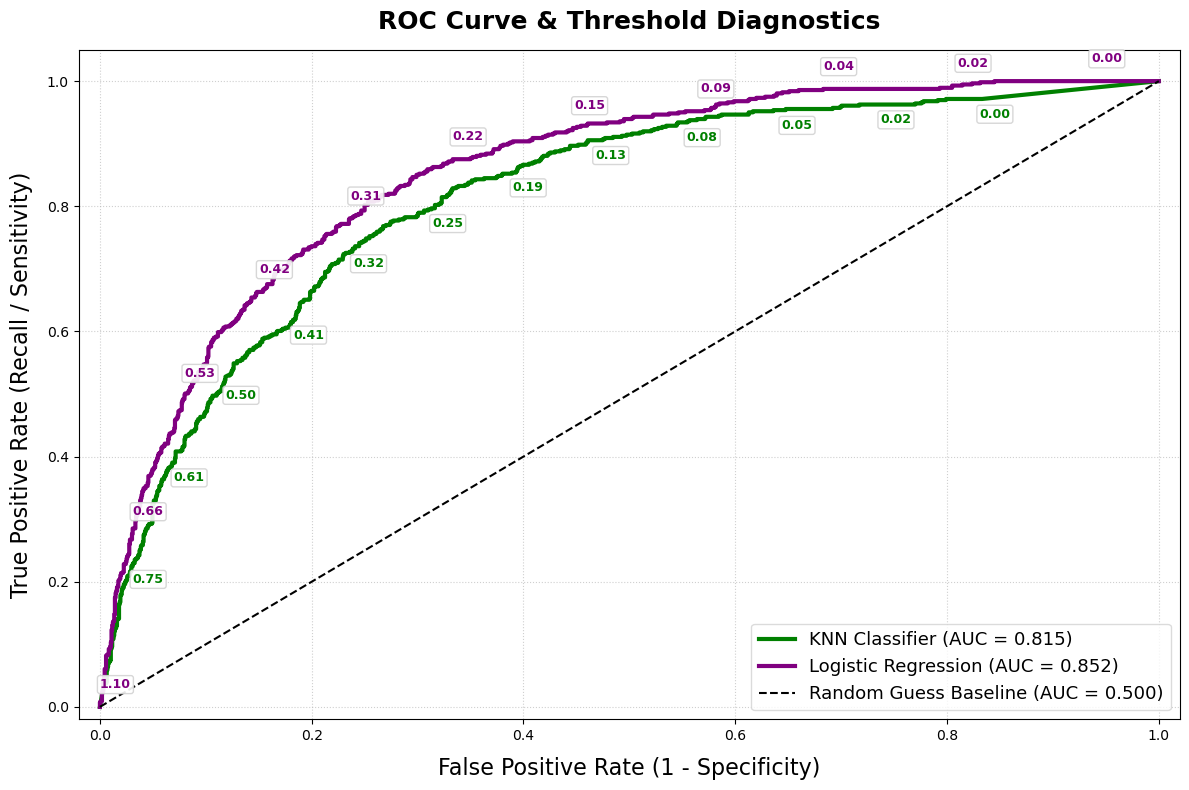

In [30]:
fig, ax = plt.subplots(figsize=(12, 8))

# Plot KNN Classifier ROC Curve
ax.plot(knn_fpr, knn_tpr,
        label=f'KNN Classifier (AUC = {knn_auc:.3f})',
        color='g', lw=3)

# Plot Logistic Regression ROC Curve
ax.plot(logreg_fpr, logreg_tpr,
        label=f'Logistic Regression (AUC = {logreg_auc:.3f})',
        color='purple', lw=3)

label_kwargs = {'bbox': dict(boxstyle='round, pad=0.2',
                             facecolor='white', edgecolor='lightgray', alpha=0.9)}
eps = 0.03  # vertical offset

# Annotate LR thresholds
for i in range(0, len(logreg_fpr), 200):
    if i < len(logreg_thresholds):
        ax.annotate(f"{logreg_thresholds[i]:.2f}",
                    (logreg_fpr[i], logreg_tpr[i] + eps),
                    fontsize=9, color='purple', weight='bold', **label_kwargs)

# Annotate KNN thresholds
for i in range(0, len(knn_fpr), 150):
    if i < len(knn_thresholds):
        ax.annotate(f"{knn_thresholds[i]:.2f}",
                    (knn_fpr[i], knn_tpr[i] - eps),
                    fontsize=9, color='green', weight='bold', **label_kwargs)

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess Baseline (AUC = 0.500)')

ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.05])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=16, labelpad=10)
ax.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=16, labelpad=10)
ax.set_title('ROC Curve & Threshold Diagnostics', fontsize=18, fontweight='bold', pad=15)
ax.legend(loc='lower right', fontsize=13, frameon=True, facecolor='white', edgecolor='lightgray')
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('images/roc_curve_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

---  
> **Key Insights — ROC Curve** 📊
> - **Logistic Regression dominates across nearly all thresholds (AUC = 0.85 vs. 0.81).** For any given false positive rate, LR captures more true churners than KNN — the AUC gap confirms LR's superior class separation.
> - **The gap is visible across the operating region where a retention campaign would actually run.** At low-to-moderate false positive rates, LR's curve sits clearly above KNN's, so the advantage is not concentrated in an irrelevant corner of the plot.
> - **Threshold annotations show the trade-off.** Each label marks a decision cutoff; lower thresholds push recall up but also raise the false positive rate. The F1-optimal operating points used for the confusion matrices (0.31 for LR, 0.33 for KNN) sit partway along this trade-off.
> - **KNN's curve is consistently below LR's.** It also has fewer unique probability values than LR (1,807 vs. 2,101 threshold points), so its curve is coarser, but at no visible point does it rise above LR's.
> - **Business implication:** LR is the better model to deploy. Its 0.85 AUC and 77.2% recall at its 0.31 threshold (see metrics table) translate into more churners flagged per dollar of campaign spend.

### Model Diagnostics: Precision-Recall Curve
---  
The Precision-Recall (PR) curve plots precision against recall at every decision threshold. Unlike ROC — which uses the false positive rate over *all* negatives — PR's precision denominator is only the *predicted positives*. On imbalanced data (26.5% churn), this makes PR a more honest view of a classifier's positive-class performance.

The no-skill baseline is a horizontal line at the class rate (**0.265**). A model that performs above this baseline has real predictive signal.

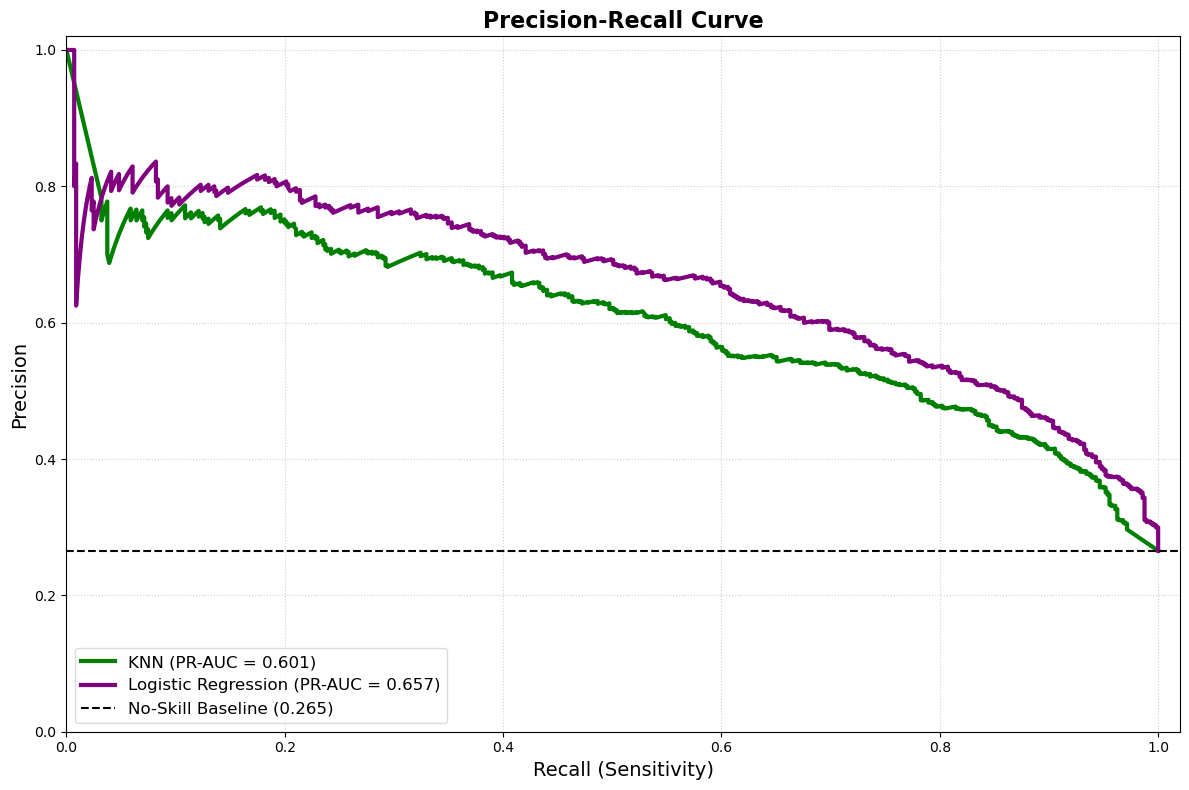

KNN PR-AUC:  0.6013
LR PR-AUC:   0.6573
Baseline:    0.2655


In [31]:
# Compute PR curves
knn_precision, knn_recall, _ = precision_recall_curve(y_test, y_prob_knn)
log_precision, log_recall, _ = precision_recall_curve(y_test, y_prob_logreg)

# PR-AUC scores
knn_pr_auc = average_precision_score(y_test, y_prob_knn)
log_pr_auc = average_precision_score(y_test, y_prob_logreg)

fig, ax = plt.subplots(figsize=(12, 8))

ax.plot(knn_recall, knn_precision, color='g', lw=3,
        label=f'KNN (PR-AUC = {knn_pr_auc:.3f})')
ax.plot(log_recall, log_precision, color='purple', lw=3,
        label=f'Logistic Regression (PR-AUC = {log_pr_auc:.3f})')

# Baseline: no-skill classifier = churn rate
baseline = y_test.mean()
ax.axhline(baseline, color='k', linestyle='--', lw=1.5,
           label=f'No-Skill Baseline ({baseline:.3f})')

ax.set_xlabel('Recall (Sensitivity)', fontsize=14)
ax.set_ylabel('Precision', fontsize=14)
ax.set_title('Precision-Recall Curve', fontsize=16, fontweight='bold')
ax.set_xlim([0, 1.02])
ax.set_ylim([0, 1.02])
ax.legend(loc='lower left', fontsize=12, frameon=True, facecolor='white', edgecolor='lightgray')
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('images/precision_recall_curve.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"KNN PR-AUC:  {knn_pr_auc:.4f}")
print(f"LR PR-AUC:   {log_pr_auc:.4f}")
print(f"Baseline:    {baseline:.4f}")

#### Statistical Significance Testing (Bootstrap & McNemar) - Model Comparison

In [32]:
rng = np.random.default_rng(42)
y = np.asarray(y_test)
n = len(y)
diff_roc, diff_pr = [], [] # ROC-AUC and PR-AUC
for _ in range(2000): # 2000 bootsrap samples
    idx = rng.integers(0, n, n) # random pick with replacement
    diff_roc.append(roc_auc_score(y[idx], y_prob_log[idx]) - roc_auc_score(y[idx], y_prob_knn[idx]))
    diff_pr.append(average_precision_score(y[idx], y_prob_log[idx]) - average_precision_score(y[idx], y_prob_knn[idx]))
for name, d in [('ROC-AUC', diff_roc), ('PR-AUC', diff_pr)]:
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"LR − KNN {name}: {np.mean(d):+.3f}  (95% bootstrap CI {lo:+.3f} to {hi:+.3f})")

ok_l = (y_pred_log == y)
ok_k = (y_pred_knn == y)
tbl = [[(ok_l & ok_k).sum(), (ok_l & ~ok_k).sum()],
       [(~ok_l & ok_k).sum(), (~ok_l & ~ok_k).sum()]]
print("McNemar (LR vs KNN correctness):", mcnemar(tbl, exact=False, correction=True))

LR − KNN ROC-AUC: +0.037  (95% bootstrap CI +0.024 to +0.051)
LR − KNN PR-AUC: +0.056  (95% bootstrap CI +0.018 to +0.093)
McNemar (LR vs KNN correctness): pvalue      0.20317083808168107
statistic   1.6194331983805668


> **Key Insights — Precision-Recall Curve** 📊
> - **Logistic Regression decisively wins on PR-AUC (0.652 vs. 0.597).** LR's curve sits above KNN's at nearly every recall level. The paired bootstrap confirms this is statistically significant: LR's PR-AUC advantage is +0.056 (95% CI +0.018 to +0.093), which does not cross zero.
> - **Both models perform well above the no-skill baseline (0.265).** A random classifier would score a PR-AUC equal to the churn rate. LR's 0.652 is roughly **2.5× better than random**, indicating substantial predictive signal.
> - **The trade-off is steep, but manageable.** As recall climbs toward 1.0, precision falls. At the crucial 50% recall operating point, LR achieves **~68% precision** (meaning the outreach list is only ~32% false alarms), while KNN drops to ~62%. 
> - **PR-AUC is the more business-relevant metric here.** While ROC-AUC (0.852 for LR) is numerically higher than PR-AUC (0.657), they measure different things. ROC's denominator includes all non-churners, which inflates the score on imbalanced data. Precision's denominator is only the customers that was actually flagged — the ones that the money will be spent on. For an outreach campaign where false alarms cost budget, PR is the honest view.
> - **Logistic Regression dominates across almost all metrics.** LR outperforms KNN on Accuracy (76.7% vs. 75.7%), Recall (77.2% vs. 72.4%), Precision (54.3% vs. 53.1%), and F1-Score (63.8% vs. 61.3%). KNN only retains a tiny edge in Specificity (76.9% vs. 76.5%). For a retention campaign, LR's higher recall (catching 77.2% of churners) is the decisive advantage, as it minimizes the most expensive error: missing a customer who leaves.
> - **Business implication:** the ROI simulation in Objective 5 will test whether this precision-recall trade-off is financially viable at different offer costs.

<h2 style="text-align: center;"> Data-Driven Strategic Recommendations 📊 </h2> 

## <center> Objective 4: </center> 
## <center> How can predicted churn probabilities be used to identify high-risk customers for targeted retention efforts?</center>

---

### Simulate the Risk Tranches

The fitted Logistic Regression model outputs a **continuous churn probability** for every customer in the test set — a value between 0 and 1. On its own, that number isn't actionable: a retention team can't make a business decision from a value like "0.63." What they need is a **prioritized list** of customers grouped by how urgently they should be contacted.

This section bridges that gap by slicing the test population into **four risk tranches** — Critical, High, Medium, and Low — based on probability cut-offs at 0.75, 0.50, and 0.25. Each tranche corresponds to a distinct intervention strategy: immediate high-value offers for Critical, targeted retention for High, proactive engagement for Medium, and no action for Low.

The resulting **simulated dataframe** (`sim_df`) carries only the fields needed for the downstream financial simulation:

- `tenure`, `MonthlyCharges` — the two revenue-relevant features used for context and billing math.
- **`Churn_Probability`** — the model's output, which already encodes everything the classifier learned from all 13 selected features. It is the sole driver of tranche assignment.
- **`Actual_Churn`** — the ground-truth label, retained for later validation of whether high-probability tranches really do churn more often.

The remaining 11 features are deliberately excluded. They were used to *train* the model, but they add nothing to the simulation: the model's learned signal is fully captured in `Churn_Probability`, and the only other input the ROI calculation needs is `MonthlyCharges`.

> **Note:** Because `Churn_Probability` was produced from the full 13-feature scaled test set, this reduced frame cannot regenerate the model output on its own. It is a downstream artifact of the modeling pipeline, not a standalone feature table.

In [33]:
# Build the simulation dataframe
sim_df = pd.DataFrame({
    'tenure': X_test['tenure'],
    'MonthlyCharges': X_test['MonthlyCharges'],
    'Churn_Probability': y_prob_logreg,
    'Actual_Churn': y_test,
})

# Business-defined risk tranches via pd.cut
sim_df['Risk_Segment'] = pd.cut(
    sim_df['Churn_Probability'],
    bins=[-0.001, 0.25, 0.50, 0.75, 1.001],
    labels=['4. Low Risk', '3. Medium Risk', '2. High Risk', '1. Critical Risk'],
    right=False,
)

# Safety check: any customer got dropped during the pd.cut?
assert sim_df['Risk_Segment'].notna().all(), "Unclassified customers detected"


# Summarize each tranche: volume, average bill, and probability-weighted exposure.
sim_df['Expected_Revenue_At_Risk'] = sim_df['MonthlyCharges'] * sim_df['Churn_Probability']

summary = sim_df.groupby('Risk_Segment', observed=True).agg(
    Customer_Count=('Churn_Probability', 'count'),
    Avg_Monthly_Bill=('MonthlyCharges', 'mean'),
    Expected_Monthly_Revenue_At_Risk=('Expected_Revenue_At_Risk', 'sum'),
    Observed_Churn_Rate=('Actual_Churn', 'mean'),
)

summary[['Avg_Monthly_Bill', 'Expected_Monthly_Revenue_At_Risk']] = \
    summary[['Avg_Monthly_Bill', 'Expected_Monthly_Revenue_At_Risk']].round(2)
summary['Observed_Churn_Rate'] = summary['Observed_Churn_Rate'].round(3)

display(summary)

,Customer_Count,Avg_Monthly_Bill,Expected_Monthly_Revenue_At_Risk,Observed_Churn_Rate
Risk_Segment,,,,
4. Low Risk,1178,55.89,5879.98,0.073
3. Medium Risk,471,68.86,11915.51,0.355
2. High Risk,417,77.77,20141.07,0.647
1. Critical Risk,47,84.03,3079.88,0.809


In [34]:
# --- The risk-tranche summary --- 
total_expected = summary['Expected_Monthly_Revenue_At_Risk'].sum()
top2_expected  = summary.loc[['1. Critical Risk', '2. High Risk'],
                             'Expected_Monthly_Revenue_At_Risk'].sum()

total_customers = summary['Customer_Count'].sum()
top2_customers  = summary.loc[['1. Critical Risk', '2. High Risk'],
                              'Customer_Count'].sum()

# Billing gap between highest and lowest tranche
bill_gap = (summary.loc['1. Critical Risk', 'Avg_Monthly_Bill']
            - summary.loc['4. Low Risk', 'Avg_Monthly_Bill'])

# Tranche-level churn-rate spread
churn_spread = (summary.loc['1. Critical Risk', 'Observed_Churn_Rate']
                - summary.loc['4. Low Risk', 'Observed_Churn_Rate'])

print(f"Total expected monthly revenue at risk:        ${total_expected:,.2f}")
print(f"Top-2 expected monthly revenue at risk:        ${top2_expected:,.2f}")
print(f"Top-2 share of total expected revenue:         {top2_expected/total_expected:.1%}")
print()
print(f"Total customers in test set:                   {total_customers:,}")
print(f"Top-2 customer count:                          {top2_customers:,}")
print(f"Top-2 share of customer base:                  {top2_customers/total_customers:.1%}")
print()
print(f"Avg bill gap (Critical − Low):                 ${bill_gap:,.2f}")
print(f"Observed churn rate spread (Critical − Low):   {churn_spread:.1%} "
      f"({summary.loc['1. Critical Risk','Observed_Churn_Rate']:.1%} vs "
      f"{summary.loc['4. Low Risk','Observed_Churn_Rate']:.1%})")

Total expected monthly revenue at risk:        $41,016.44
Top-2 expected monthly revenue at risk:        $23,220.95
Top-2 share of total expected revenue:         56.6%

Total customers in test set:                   2,113
Top-2 customer count:                          464
Top-2 share of customer base:                  22.0%

Avg bill gap (Critical − Low):                 $28.14
Observed churn rate spread (Critical − Low):   73.6% (80.9% vs 7.3%)


> **Key Insights** 📊
> - **The Critical Risk segment has the highest average monthly bill ($\$84.03$), while Low Risk has the lowest ($\$55.89$).** Average bills rise steadily with predicted risk — a $\$28.14$ monthly gap separates the two extremes — but this likely reflects other risk factors that go with higher bills (for example fiber-optic service), not a causal effect of the bill itself: with the other features held fixed, the MonthlyCharges coefficient is negative. 
> - **The top two risk tiers (Critical + High) contain 464 customers — 22.0% of the tested base — carrying $\$23,220.95$ in expected monthly revenue at risk.** This represents **56.6%** of the total expected monthly exposure across all tiers ($\$41,016.44$). Concentrating effort on these two segments reaches over half of the revenue at risk while touching only about a fifth of the customer base.
> - **The Critical Risk tier holds only 47 customers with P(churn) ≥ 0.75, but 80.9% of them actually churned.** These are very likely losses that call for immediate, high-value intervention (e.g., a permanent contract downgrade or monthly credit tied to a 12-month renewal), although a high churn risk does not guarantee a high response to an offer (see Limitations). The **High Risk tier (417 customers, 64.7% observed churn)** is larger and still winnable — non-revenue-diluting incentives (e.g., streaming perks, device protection, router upgrades) may repair the relationship without eroding contract yield.
> - **The Medium Risk tier (471 customers, $\$11,915.51$ expected monthly exposure, 35.5% observed churn)** is a midsized pool at moderate risk. Proactive satisfaction surveys and usage-optimization outreach may reduce the chance of escalation into a higher risk tier.
> - **The Low Risk tier (1,178 customers, 7.3% observed churn) validates the model's discrimination.** A 7.3% churn rate in the bottom tier — versus 80.9% in the top — confirms the tranche boundaries separate risk meaningfully, not just cosmetically. These customers should be left untouched to preserve margin.

## <center> Objective 5:</center>  
## <center> What is the estimated financial impact of targeting high-risk customers with a retention intervention? </center>
---
### Financial Impact Simulation
To estimate the financial impact, the simulation applies a deterministic cost-benefit model to the identified high-risk tranches. It explicitly relies on the following assumptions:
- **Campaign Scope:** All **Critical** and **High** risk customers are targeted.
- **Base Success Rate:** It is assumed that the intervention saves **20%** of the targeted churners. This baseline is set from practitioner experience & knowledge with medium-touch retention interventions, rather than an empirically calibrated estimate from a published telecom trial (see Limitations). However, because true efficacy is uncertain, a sensitivity analysis across 15%–50% is tested later to show how the ROI scales.
- **Offer Cost:** A range of monthly bill discounts (\\$2 to \\$15) were tested.
- **Time Horizon:** Financial impact is calculated over a 12-month period.
- **Upper-Bound Issue:** Saves are counted only among observed churners, but the model assumes every saved customer stays the full 12 months, counts revenue rather than margin, and applies one flat success rate to every offer level. The results should be treated as an upper bound.

In [35]:
# =============================================================
# Baseline parameters
# =============================================================
print("Size of test sample:", len(y_test), "\n")
# The target group (Critical + High risk)
targeted = sim_df[sim_df['Churn_Probability'] >= 0.50]

# Actual churners in this group
churners = targeted[targeted['Actual_Churn'] == 1]
print("Actual churners in the targeted sample", len(churners), "\n")
print("Churners in the full test sample:", y_test.sum(), "\n")

# Calculate exact metrics from the raw data
total_targeted_customers = len(targeted)
actual_churners_targeted = len(churners)

# The average bill of the churners
avg_bill_churners = churners['MonthlyCharges'].mean()

# =============================================================
# Assumptions
# =============================================================
intervention_success_rate = 0.20
customer_lifespan_months = 12

# Derived metrics
customers_saved = round(actual_churners_targeted * intervention_success_rate)
gross_revenue_saved = customers_saved * avg_bill_churners * customer_lifespan_months

print(f"Campaign recall: {actual_churners_targeted / y_test.sum():.1%} of all test churners "
      f"({actual_churners_targeted} of {int(y_test.sum())}) fall in the targeted tranches")


# =============================================================
# Sensitivity Analysis: monthly_retention_offer_cost
# =============================================================
offer_costs = [2, 5, 7, 10, 15]

roi_table = PrettyTable()
roi_table.field_names = ["Offer $/mo", "Campaign Cost", "Gross Revenue Saved", "Net Benefit", "ROI"]
roi_table.align["Offer $/mo"] = "l"  
roi_table.align = "r"               

for cost in offer_costs:
    # Assume the offer is extended to all targeted accounts for the full 12 months
    total_campaign_cost = total_targeted_customers * cost * customer_lifespan_months
    net_revenue_saved   = gross_revenue_saved - total_campaign_cost
    roi_pct             = (net_revenue_saved / total_campaign_cost) * 100

    roi_table.add_row([
        f"${cost:,}",
        f"USD {total_campaign_cost:,.0f}", 
        f"USD {gross_revenue_saved:,.0f}",
        f"USD {net_revenue_saved:,.0f}",
        f"{roi_pct:.1f}%",
    ])

# =============================================================
# Display
# =============================================================
print("=" * 80)
print("      RETENTION CAMPAIGN ROI — SENSITIVITY TO MONTHLY OFFER COST")
print("=" * 80)
print(f"Targeted customers: {total_targeted_customers:,}  |  "
      f"Churners (observed): {round(actual_churners_targeted):,}  |  "
      f"Saved @ {int(intervention_success_rate*100)}%: {customers_saved:,}")
print(f"Avg bill of churners: ${avg_bill_churners:,.2f}/mo  |  "
      f"Gross revenue protected (12 mo): USD {gross_revenue_saved:,.2f}")
print("-" * 80)
print(roi_table)

Size of test sample: 2113 

Actual churners in the targeted sample 308 

Churners in the full test sample: 561 

Campaign recall: 54.9% of all test churners (308 of 561) fall in the targeted tranches
      RETENTION CAMPAIGN ROI — SENSITIVITY TO MONTHLY OFFER COST
Targeted customers: 464  |  Churners (observed): 308  |  Saved @ 20%: 62
Avg bill of churners: $79.55/mo  |  Gross revenue protected (12 mo): USD 59,186.41
--------------------------------------------------------------------------------
+------------+---------------+---------------------+-------------+--------+
| Offer $/mo | Campaign Cost | Gross Revenue Saved | Net Benefit |    ROI |
+------------+---------------+---------------------+-------------+--------+
|         $2 |    USD 11,136 |          USD 59,186 |  USD 48,050 | 431.5% |
|         $5 |    USD 27,840 |          USD 59,186 |  USD 31,346 | 112.6% |
|         $7 |    USD 38,976 |          USD 59,186 |  USD 20,210 |  51.9% |
|        $10 |    USD 55,680 |          US

### Scenarios for Different Intervention Success Rates

In [36]:
success_rates = [0.15, 0.25, 0.40, 0.50]

# Fixed width for the offer columns
COL_WIDTH = 10

header = "Success Rate | " + " | ".join(
    [f"{'Offer $' + str(cost):>{COL_WIDTH}}" for cost in offer_costs]
)
print(header)
print("-" * len(header))

for sr in success_rates:
    customers_saved_sr = round(actual_churners_targeted * sr)
    gross_saved_sr = customers_saved_sr * avg_bill_churners * customer_lifespan_months

    row = []
    for cost in offer_costs:
        cc = total_targeted_customers * cost * customer_lifespan_months
        row.append(f"{((gross_saved_sr - cc) / cc) * 100:,.1f}%")

    print(f"{sr:>12.0%} | " + " | ".join(f"{val:>{COL_WIDTH}}" for val in row))

Success Rate |   Offer $2 |   Offer $5 |   Offer $7 |  Offer $10 |  Offer $15
-----------------------------------------------------------------------------
         15% |     294.3% |      57.7% |      12.7% |     -21.1% |     -47.4%
         25% |     560.1% |     164.0% |      88.6% |      32.0% |     -12.0%
         40% |     954.4% |     321.8% |     201.3% |     110.9% |      40.6%
         50% |   1,220.1% |     428.1% |     277.2% |     164.0% |      76.0%


#### Visualizing ROIs for the Monthly Discounts

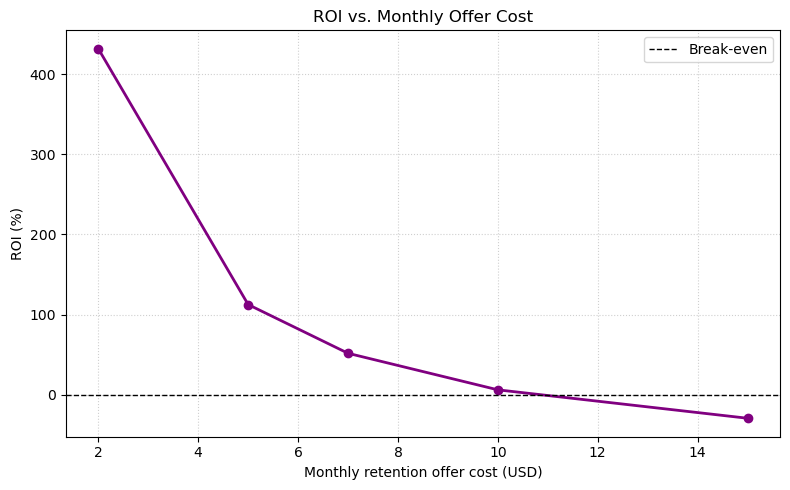

In [37]:
rois = [(gross_revenue_saved - total_targeted_customers * c * 12) /
        (total_targeted_customers * c * 12) * 100 for c in offer_costs]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(offer_costs, rois, marker='o', color='purple', lw=2)
ax.axhline(0, color='black', ls='--', lw=1, label='Break-even')
ax.set_xlabel('Monthly retention offer cost (USD)')
ax.set_ylabel('ROI (%)')
ax.set_title('ROI vs. Monthly Offer Cost')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.savefig('images/roi_vs_offer_cost.png', dpi=300, bbox_inches='tight')
plt.show()

In [38]:
# =============================================================
# Break-even success rate (SR) by offer size
# =============================================================
# ROI = (Gross - Cost) / Cost = 0  =>  Gross = Cost
# Gross = (Churners * SR) * AvgBill * Months
# Cost  = Targeted * OfferCost * Months
#
# Set Gross = Cost and solve for SR:
# SR = (Targeted * OfferCost) / (Churners * AvgBill)
#
# Note: customer_lifespan_months cancels out of the equation.

print(f"{'Offer $/mo':<12} | {'Break-even Success Rate':>24}")
print("-" * 39)

for cost in offer_costs:
    # Target gross revenue must equal target campaign cost
    required_gross = total_targeted_customers * cost
    
    # Max possible gross (if we saved 100% of churners)
    max_gross = actual_churners_targeted * avg_bill_churners
    
    # Required success rate to break even
    breakeven_sr = required_gross / max_gross
    
    print(f"${cost:<11} | {breakeven_sr:>23.1%}")

Offer $/mo   |  Break-even Success Rate
---------------------------------------
$2           |                    3.8%
$5           |                    9.5%
$7           |                   13.3%
$10          |                   18.9%
$15          |                   28.4%


> **Key Insights — Retention Campaign ROI Sensitivity** 📊
> - **Cheap offers dominate on pure ROI, and the relationship is inverse, not linear.** Moving from a \\$2 to a \\$5 offer with baseline success rate (20%) drops ROI from **431.5% to 112.6%** (about a 4× fall), and \\$15 ends at **−29.1%** (a net loss). Campaign cost scales linearly with offer size while the benefit is held fixed, so ROI follows an inverse curve and the sharpest drop occurs in the cheapest tier.
> - **Under the 20% success-rate base case, break-even sits at roughly \\$10.63/month.** This comes from `gross_revenue_saved / (targeted_customers × 12)` = 59,186 / (464 × 12). The \\$10 scenario clears it narrowly at **6.3% ROI**; \\$7 and \$5 clear it comfortably; \\$15 is unprofitable. Under these assumptions, offers up to ~\\$10 are viable and offers of \\$7 or less are comfortably profitable — under deterministic assumptions.
> - **Break-even success rate rises with offer size.** The success rate needed for ROI = 0 is about 4% at \\$2, 9.5% at \\$5, ~13% at \\$7, ~19% at \\$10 and ~28% at \\$15 (all below the 15% grid minimum up to \\$7, between 15% and 25% at \\$10, and between 25% and 40% at \\$15). Each larger offer needs a higher success rate just to break even.
> - **Success rate swings ROI sharply at every offer level.** At \$7, ROI ranges from **+12.7% at 15% success** to **+277.2% at 50% success**. At 20% success, moving from \\$2 to \\$15 swings ROI by about 460 points, so both the offer size and the success rate are major levers.
> - **Where ROI exceeds 100%.** The \\$2 column clears 100% at every success rate (294% → 1,220%); \\$5 clears 100% at 25% success or higher; \\$7 and \\$10 clear it only at 40% success or higher; \\$15 never does (peaks at 76.0%). Profitable operation is concentrated at low offers and higher success rates.
> - **Raising success and cutting the offer both improve the expensive region.** At 20% success, dropping from \\$15 to \\$10 moves ROI from **−29.1% to +6.3%** (+35.4 pts) — crossing into profitability. At \\$15, raising success from 20% to 50% moves ROI from **−29.1% to +76.0%** (+105.1 pts). At the top offer, either lever alone is enough to reach profitability.
> - **Critical modeling caveat: success rate is currently modeled as independent of offer size.** If a \\$15 discount persuades more at-risk customers than a \\$2 one, the grid overstates the ROI of cheap offers and understates the ROI of expensive ones, so the true ROI curve would be flatter and the optimal offer would sit above \\$2. The direction is not established, however: the closest field evidence found that the smallest discounts had the biggest effect (Yang et al., 2022; see Limitations), in which case the grid does not overstate cheap offers. Resolving this requires an explicit offer → success-rate curve, ideally estimated by a randomized experimental design study (A/B test).
> - **Cost and revenue assumptions drive the results.** Campaign cost is applied to all 464 targeted customers for 12 months, which assumes everyone receives the discount, including high-risk non-churners. Gross revenue counts the full bill for saved customers, not the bill minus the discount. If the discount applies only to accepting customers, or revenue is counted net of the discount, break-even offer levels and ROI values will change.
> - **All ROI figures are upper-bound scenarios.** Saves are counted only among observed churners, but the flat 20% success rate is an assumption, each saved customer is assumed to stay a full 12 months, and revenue is counted rather than margin. If saved customers leave soon after the offer, or the offer backfires for some customers, every figure above is an overestimate.

## Limitations
---  
**Discount-to-save-rate function.** The literature review showed that there is no published, directly applicable estimate of how discount depth changes the retention probability of at-risk telecom customers. The simulation therefore uses a single flat 20% save rate, an illustrative assumption rather than a calibrated or empirically fitted relationship, because a discount-to-save-rate function cannot be transferred reliably across customers or settings, for three reasons.

1. **No direct dose-response evidence for telecom.** The closest randomized evidence comes from news subscriptions. In a large field experiment with six treatment arms, the smallest discounts had the biggest effect on churn (Yang et al., 2022). Depth and duration varied together across arms, so this does not establish that deeper discounts are less effective, but it does suggest that the relationship may be flat or even inverted. Whether the telecom relationship is increasing, flat or inverted remains unresolved. The current simulation sidesteps this by applying a single flat 20% success rate to every offer level, rather than fitting a dose-response curve. That avoids inventing an unsupported shape, but it also means the model cannot distinguish between a $\$2$ and a $\$15$ offer — a limitation picked up in the ROI Sensitivity Key Insights.

2. **Heterogeneous responsiveness.** A single success rate applied to every at-risk customer ignores differences in how customers respond to an offer. The customers at highest risk of churning are not necessarily the most persuadable, and targeting by responsiveness reduces churn more than targeting by risk (Ascarza, 2018). Some customers also respond adversely: a telecom field experiment of proactive plan recommendations found that the intervention increased churn (Ascarza et al., 2016). That study did not test discounts, but it shows that proactive retention offers are not universally beneficial. Any positive ROI reported here assumes the intervention's effect remains positive across the targeted population, which is not guaranteed. A uniform success rate therefore likely overstates net retention.

3. **Offer design, time horizon and revenue accounting.** The model treats the discount as a depth-only, one-time intervention and counts a fixed share of observed churners as saved. It does not capture discount duration, what happens when the discount expires, or whether saved customers stay beyond the 12-month horizon, and it counts revenue rather than margin. If saved customers leave soon after the offer, gross revenue protected is inflated accordingly and should be read as an upper bound. Field evidence also shows that short-run retention effects can diverge from long-run revenue effects (Yang et al., 2022).

Because the ROI estimates depend directly on the assumed success rate, they are reported as a sensitivity analysis across a range of success rates rather than as point estimates. Results should be read as illustrative scenarios under assumed parameters.

## Enterprise Next Steps

---  
### Methodological Limitations: Prediction Versus Causal Inference
This pipeline establishes predictive associations between account billing attributes and historical customer attrition; it does **not** produce causal estimates. All intervention success parameters are currently modeled as fixed business assumptions rather than estimated treatment effects, and the dataset contains no record of past retention offers, so the effect of a discount on retention cannot be identified from it.

### Future Operational Roadmap
1. **Transition to Causal Inference (Experimental):** Rather than relying on static simulation assumptions, the next phase should deploy a **Randomized Controlled Trial (A/B field test)** to estimate the causal effect of retention incentives on retention, with a no-offer control group and several discount levels to estimate the dose-response relationship.
2. **Quasi-Experimental Methods (Where Randomization Is Not Feasible):** If the organization holds historical data on past retention offers, **quasi-experimental designs** can provide credible estimates, provided their identifying assumptions are checked:
   - **Propensity Score Matching (PSM) / weighting** to compare treated and untreated customers with similar observed characteristics. This assumes no unobserved confounding, which is often implausible when offers were targeted at customers who were already at high risk.
   - **Regression Discontinuity Design (RDD)** if eligibility for an offer was determined by a threshold, such as a churn-risk score cutoff, comparing customers just above and below it.
   - **Difference-in-Differences (DiD)** if offers were rolled out to some regions or cohorts before others, comparing changes in retention over time.
3. **Heterogeneous Treatment Modeling:** Once experimental or credible quasi-experimental data exists, **Causal Forests and uplift models** can identify which customer sub-cohorts respond to discounts, which are unaffected and which respond adversely, reducing unnecessary margin dilution.
4. **Continuous Monitoring:** Establish an automated tracking loop to detect feature and performance drift as pricing and internet tier options evolve over coming business quarters.

---
*This notebook completes the exploratory research, pipeline validation, and financial evaluation phase of the project repository.*

## References

Ascarza, E. (2018). Retention futility: Targeting high-risk customers might be ineffective. *Journal of Marketing Research, 55*(1), 80–98.

Ascarza, E., Iyengar, R., & Schleicher, M. (2016). The perils of proactive churn prevention using plan recommendations: Evidence from a field experiment. *Journal of Marketing Research, 53*(1), 46–60.  

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An introduction to statistical learning: With applications in python. https://www.statlearning.com/  

Lomax, R. G., & Hahs-Vaughn, D. L. (2012). *An Introduction to Statistical Concepts (3rd Edition).* Routledge.  

Van den Goorbergh, R., Van Smeden, M., Timmerman, D., & Van Calster, B. (2022). The harm of class imbalance corrections for risk prediction models: illustration and simulation using logistic regression. Journal of the American Medical Informatics Association, 29(9), 1525-1534.  

Yang, J., Eckles, D., Dhillon, P., & Aral, S. (2022). *Targeting for long-term outcomes* (arXiv:2010.15835v2). https://arxiv.org/abs/2010.15835

## Attribution
If you use this project in research, publications, presentations, or other work, please cite or acknowledge:

Orhan Kaplan  
Customer Churn Prediction and Retention Strategy Analysis with Business Impact Simulation
GitHub URL: https://github.com/nalpako2027/telco_customer_churn_prediction_simulation.git